In [6]:
import pandas as pd
import numpy as np

In [11]:
df = pd.read_csv("../data/bronze/Property.csv", sep = ";")

In [13]:
df.head(1)

,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,baths,area,purpose,bedrooms,date_added,agency,agent
0,347795,8,https://www.zameen.com/Property/lahore_model_t...,House,220000000,Model Town,Lahore,Punjab,31.483869,74.325686,0,6 Kanal,For Sale,0,07-17-2019,Real Biz International,Usama Khan


Limpieza general

In [14]:
df = df.drop(columns=["property_id","agency","agent","location_id","page_url"])

In [15]:
print(len(df))
df = df.drop_duplicates()
print(len(df))

191393
168615


Limpieza Variables:

Primera vuelta limpieza: 

Variable baths

In [16]:
df["baths"].value_counts()

baths
0      40688
3      33073
2      25326
4      20611
6      17349
5      16119
1       5840
7       5735
8       2133
10       962
9        754
12        10
11         7
13         3
14         3
403        1
15         1
Name: count, dtype: int64

In [17]:
df = df[df["baths"] < 7]

In [18]:
len(df)

159006

Variable bedrooms: 

In [19]:
df["bedrooms"].value_counts()

bedrooms
3     45007
2     30745
4     23955
5     22942
0     19991
6      8787
1      5065
7       986
8       695
9       348
10      337
11       87
12       25
15        8
14        7
16        4
25        4
13        3
28        3
20        2
27        2
18        1
68        1
21        1
Name: count, dtype: int64

In [20]:
df = df[df["bedrooms"]<7]
len(df)

156492

Variables bedroom - bathroom conjuntas: 

In [21]:
df.groupby("bedrooms")["baths"].value_counts().unstack(fill_value=0)

baths,0,1,2,3,4,5,6
bedrooms,,,,,,,
0,19632,84,96,71,39,29,40
1,695,3676,670,17,4,2,1
2,4396,1762,20846,3541,158,23,19
3,6527,249,2609,27031,7791,754,46
4,3419,47,827,1396,11145,6086,1035
5,3085,9,168,586,854,8442,9798
6,1962,7,82,309,367,492,5568


In [22]:
df = df[~((df["bedrooms"] == 0) & (df["baths"] > 0))].reset_index(drop=True)

In [23]:
df = df[~((df["baths"] == 0) & (df["bedrooms"] > 1))].reset_index(drop=True)

In [24]:
n_antes = len(df)
df = df.query("not (bedrooms == 0 and baths == 0)").reset_index(drop=True)
print(f"Filas eliminadas: {n_antes - len(df)}")

Filas eliminadas: 19632


Variable city:

In [25]:
df["city"].value_counts()

city
Lahore        39368
Karachi       38185
Islamabad     24288
Rawalpindi    12906
Faisalabad     2365
Name: count, dtype: int64

Variable date_added: 

In [26]:
df["date_added"] = pd.to_datetime(df["date_added"])
df["date_added"].dtype

dtype('<M8[ns]')

Variable location: 

In [27]:
df["location"].nunique()

1430

In [28]:
CENTROS = {
    "Lahore":     (31.582045, 74.329376),
    "Karachi":    (24.860966, 66.990501),
    "Islamabad":  (33.738045, 73.084488),
    "Rawalpindi": (33.626057, 73.071442),
    "Faisalabad": (31.418715, 73.079109),
}
R_TIERRA_KM = 6371.0088

lat_c = df["city"].map(lambda c: CENTROS[c][0])
lon_c = df["city"].map(lambda c: CENTROS[c][1])

lat1, lon1 = np.radians(df["latitude"]), np.radians(df["longitude"])
lat2, lon2 = np.radians(lat_c), np.radians(lon_c)

# Fórmula de Haversine (distancia en línea recta sobre la esfera, en km)
a = np.sin((lat1 - lat2) / 2) ** 2 + np.cos(lat2) * np.cos(lat1) * np.sin((lon1 - lon2) / 2) ** 2
df["dist_centro_km"] = (2 * R_TIERRA_KM * np.arcsin(np.sqrt(a))).round(2)

df.groupby("city")["dist_centro_km"].describe()

,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Faisalabad,2365.0,7.917082,80.818818,0.00,4.07,5.72,7.36,3932.06
Islamabad,24288.0,14.341343,53.254759,0.72,9.33,11.39,18.89,5404.75
Karachi,38185.0,15.453015,13.660381,0.30,8.86,12.23,18.10,942.89
Lahore,39368.0,15.984518,6.990353,0.32,12.00,15.30,18.81,268.65
Rawalpindi,12906.0,9.816383,35.867961,0.27,6.92,8.91,13.05,4046.89


In [29]:
n_antes = len(df)
df = df[df["dist_centro_km"] <= 100].reset_index(drop=True)
print(f"Filas eliminadas por coordenadas erróneas: {n_antes - len(df)}")

Filas eliminadas por coordenadas erróneas: 24


Variable price

In [30]:
PKR_TO_EUR_2019 = 1 / 179.61   # ≈ 0.005568, valutafx, 18/07/2019

df["price"] = (df["price"] * PKR_TO_EUR_2019).round(2)

Variable property type

In [31]:
df["property_type"].value_counts()

property_type
House            68235
Flat             28326
Upper Portion    11983
Lower Portion     7256
Room               760
Penthouse          274
Farm House         254
Name: count, dtype: int64

In [32]:
df[df["property_type"] == "Room"]

,property_type,price,location,city,province_name,latitude,longitude,baths,area,purpose,bedrooms,date_added,dist_centro_km
498,Room,47.32,Doctors Housing Society,Lahore,Punjab,31.461139,74.233675,1,3 Marla,For Rent,1,2019-06-24,16.22
528,Room,30.62,Green Town,Lahore,Punjab,31.434742,74.304729,1,5 Marla,For Rent,1,2019-07-10,16.55
531,Room,41.76,Raiwind Road,Lahore,Punjab,31.429249,74.230785,1,1 Marla,For Rent,1,2019-07-10,19.39
538,Room,30.62,Green Town,Lahore,Punjab,31.434742,74.304729,0,5 Marla,For Rent,1,2019-07-10,16.55
561,Room,44.54,Gulshan-e-Iqbal Town,Karachi,Sindh,24.898465,67.062500,1,9.6 Marla,For Rent,1,2019-07-18,8.37
...,...,...,...,...,...,...,...,...,...,...,...,...,...
116863,Room,47.32,Gulberg,Lahore,Punjab,31.524245,74.346110,1,1.1 Marla,For Rent,1,2019-07-24,6.62
116867,Room,33.41,Gulberg,Lahore,Punjab,31.524245,74.346110,1,1.1 Marla,For Rent,1,2019-07-24,6.62
116894,Room,139.19,Sui Gas Housing Society,Lahore,Punjab,31.455465,74.399142,1,5 Marla,For Rent,1,2019-07-24,15.55
116938,Room,111.35,DHA Defence,Lahore,Punjab,31.483283,74.395723,1,10 Marla,For Rent,1,2019-07-24,12.65


In [33]:
mask = (df["bedrooms"] > 1) & (df["property_type"] == "Room")
print(f"Filas que cambian de Room a Flat: {mask.sum()}")

df.loc[mask, "property_type"] = "Flat"

Filas que cambian de Room a Flat: 89


Variable province_name

In [34]:
df["province_name"].value_counts()

province_name
Punjab               54631
Sindh                38181
Islamabad Capital    24276
Name: count, dtype: int64

In [35]:
df = pd.get_dummies(df, columns=["province_name"], prefix="prov", drop_first=True, dtype=int)

Variable purpose:

In [36]:
df["purpose"].value_counts()

purpose
For Sale    77141
For Rent    39947
Name: count, dtype: int64

In [37]:
df = df[df["purpose"] == "For Sale"]
df = df.drop(columns=["purpose"]).reset_index(drop=True)

In [38]:
df

,property_type,price,location,city,latitude,longitude,baths,area,bedrooms,date_added,dist_centro_km,prov_Punjab,prov_Sindh
0,House,222704.75,Multan Road,Lahore,31.431593,74.179980,5,1 Kanal,5,2018-10-06,21.92,1,0
1,House,116919.99,Allama Iqbal Town,Lahore,31.506483,74.286017,5,11 Marla,6,2019-04-04,9.35,1,0
2,House,289516.17,Gulberg,Lahore,31.495909,74.350569,6,1 Kanal,5,2019-06-02,9.79,1,0
3,House,75162.85,Eden,Lahore,31.441113,74.239683,4,7.5 Marla,4,2019-04-04,17.83,1,0
4,House,487166.64,Upper Mall,Lahore,31.542114,74.355898,5,1.2 Kanal,4,2019-06-30,5.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
77136,House,89081.90,G-13,Islamabad,33.645957,72.962472,5,4.4 Marla,4,2019-07-24,15.24,0,0
77137,House,20043.43,DHA Defence,Islamabad,33.492591,73.301339,2,5 Marla,2,2019-07-24,33.88,0,0
77138,House,94649.52,G-13,Islamabad,33.650065,72.963681,5,4 Marla,4,2019-07-24,14.85,0,0
77139,House,93535.99,G-13,Islamabad,33.650958,72.963030,5,4 Marla,4,2019-07-24,14.83,0,0


Variable Total_Area: 

In [40]:
df[["area_num", "area_unit"]] = df["area"].str.split(" ", expand=True)
df["area_num"] = df["area_num"].str.replace(",", "", regex=False).astype(float)

df["area_unit"].value_counts()

area_unit
Marla    66960
Kanal    10181
Name: count, dtype: int64

In [41]:
FT2_TO_M2 = 0.09290304
FACTORES_M2 = {
    "Marla": 272.25 * FT2_TO_M2,        # 1 marla = 272,25 ft² ≈ 25,29 m²
    "Kanal": 20 * 272.25 * FT2_TO_M2,   # 1 kanal = 20 marlas ≈ 505,86 m²
}

df["Total_Area"] = (df["area_num"] * df["area_unit"].map(FACTORES_M2)).round(2)
df = df.drop(columns=["area", "area_num", "area_unit"])

df["Total_Area"].describe()

count    7.714100e+04
mean     3.158761e+02
std      1.196843e+04
min      0.000000e+00
25%      1.188800e+02
50%      1.542900e+02
75%      2.529300e+02
max      2.276357e+06
Name: Total_Area, dtype: float64

Segunda vuelta limpieza: 

Variable property_type

In [42]:
df = df[~((df["property_type"] == "Flat") & (df["Total_Area"] > 250))].reset_index(drop=True)

In [43]:
n_antes = len(df)
df = df[~((df["property_type"] == "House") & (df["Total_Area"] > 2500))].reset_index(drop=True)
print(f"Casas eliminadas: {n_antes - len(df)}")

Casas eliminadas: 99


In [44]:
df["city"].value_counts()

city
Lahore        29127
Karachi       26637
Islamabad      9663
Rawalpindi     7167
Faisalabad     1640
Name: count, dtype: int64

Variables latitude y longitude: 

In [45]:
df = df.drop(columns=["latitude", "longitude"])

In [46]:
df

,property_type,price,location,city,baths,bedrooms,date_added,dist_centro_km,prov_Punjab,prov_Sindh,Total_Area
0,House,222704.75,Multan Road,Lahore,5,5,2018-10-06,21.92,1,0,505.86
1,House,116919.99,Allama Iqbal Town,Lahore,5,6,2019-04-04,9.35,1,0,278.22
2,House,289516.17,Gulberg,Lahore,6,5,2019-06-02,9.79,1,0,505.86
3,House,75162.85,Eden,Lahore,4,4,2019-04-04,17.83,1,0,189.70
4,House,487166.64,Upper Mall,Lahore,5,4,2019-06-30,5.10,1,0,607.03
...,...,...,...,...,...,...,...,...,...,...,...
74229,House,89081.90,G-13,Islamabad,5,4,2019-07-24,15.24,0,0,111.29
74230,House,20043.43,DHA Defence,Islamabad,2,2,2019-07-24,33.88,0,0,126.46
74231,House,94649.52,G-13,Islamabad,5,4,2019-07-24,14.85,0,0,101.17
74232,House,93535.99,G-13,Islamabad,5,4,2019-07-24,14.83,0,0,101.17


## Tercera vuelta de limpieza: superficie y precio

Tras las dos vueltas anteriores todavía quedan valores que no tienen sentido. Los buscamos y los tratamos **antes** de separar train y test, porque son reglas fijas (no aprenden de los datos).

Cada decisión sigue el esquema *hallazgo → acción → justificación → filas eliminadas*.

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

n_inicial_3v = len(df)
print(f"Filas de partida: {n_inicial_3v}")

df.groupby("property_type")["Total_Area"].agg(["count", "min", "median", "max"]).round(1)

Filas de partida: 74234


,count,min,median,max
property_type,,,,
Farm House,190,60.7,3541.0,84984.0
Flat,16857,5.1,111.3,247.9
House,54680,0.0,202.3,2326.9
Lower Portion,675,25.3,146.7,1416.4
Penthouse,202,45.5,227.6,1011.7
Room,8,17.7,58.2,505.9
Upper Portion,1622,10.1,139.1,6070.3


### Superficie (`Total_Area`)

**Hallazgo.** Los filtros de las vueltas anteriores solo cubren `Flat` (≤ 250 m²) y `House` (≤ 2.500 m²). El resto de tipos conserva superficies imposibles: la tabla muestra un máximo de casi 129.000 m² y, en el gráfico, `Upper Portion`, `Lower Portion` y `Penthouse` llegan a decenas de miles de m² cuando son una planta de una casa o un piso.

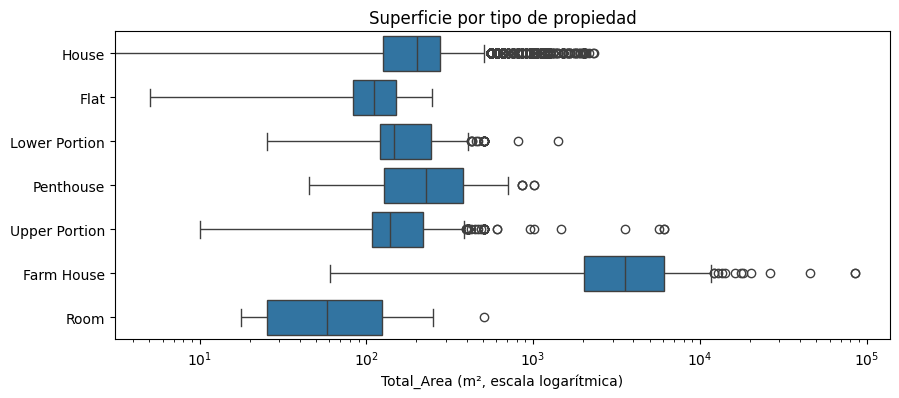

In [48]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=df, x="Total_Area", y="property_type", ax=ax)
ax.set_xscale("log")
ax.set_xlabel("Total_Area (m², escala logarítmica)")
ax.set_ylabel("")
ax.set_title("Superficie por tipo de propiedad")
plt.show()

**Decisión 1: superficie mínima.** Un anuncio con menos de 10 m² no es una vivienda real. Miramos cuáles son.

In [49]:
menores = df[df["Total_Area"] < 10]
print(f"Anuncios con Total_Area < 10 m²: {len(menores)}")
menores[["property_type", "price", "Total_Area", "bedrooms", "city"]]

Anuncios con Total_Area < 10 m²: 12


,property_type,price,Total_Area,bedrooms,city
16269,House,24497.52,0.00,2,Karachi
19976,House,69595.23,0.00,5,Lahore
34318,Flat,17816.38,5.06,2,Karachi
47255,House,1670285.62,5.06,6,Islamabad
53984,House,100217.14,0.00,3,Lahore
58697,House,91865.71,0.00,5,Islamabad
59447,House,12248.76,0.00,2,Lahore
59540,House,250542.84,2.53,5,Lahore
69036,House,25054.28,0.00,2,Lahore
69379,House,0.01,5.06,4,Islamabad


Son anuncios de casas con 2 a 5 habitaciones y **0 m²**: el cero es un dato que falta, no una superficie real. Son pocos (7 filas, el 0,01 %) y no hay forma fiable de recuperar el valor, así que **se eliminan**.

In [50]:
n_antes = len(df)
df = df[df["Total_Area"] >= 10].reset_index(drop=True)
print(f"Filas eliminadas por superficie < 10 m²: {n_antes - len(df)}")

Filas eliminadas por superficie < 10 m²: 12


**Decisión 2: superficie máxima en el resto de tipos.** Una planta de una casa (`Upper Portion`, `Lower Portion`), un `Penthouse` o una `Room` no puede ser mayor que una casa entera. Aplicamos el mismo límite que a las casas (2.500 m²).

`Farm House` **no se toca**: una granja puede ser legítimamente muy grande (la mediana es de unos 4.000 m²), así que sus valores altos son atípicos reales, no errores.

In [51]:
TIPOS_PARCIALES = ["Upper Portion", "Lower Portion", "Penthouse", "Room"]
mask = df["property_type"].isin(TIPOS_PARCIALES) & (df["Total_Area"] > 2500)
print(f"Filas que superan 2.500 m² (tipos parciales): {mask.sum()}")
print(df[mask]["property_type"].value_counts())

df = df[~mask].reset_index(drop=True)

Filas que superan 2.500 m² (tipos parciales): 4
property_type
Upper Portion    4
Name: count, dtype: int64


### Precio (`price`)

**Hallazgo.** El precio tiene una asimetría muy fuerte y, en el extremo bajo, hay anuncios con precios de unos pocos euros, que no corresponden a una venta real (probablemente alquileres o errores de escritura).

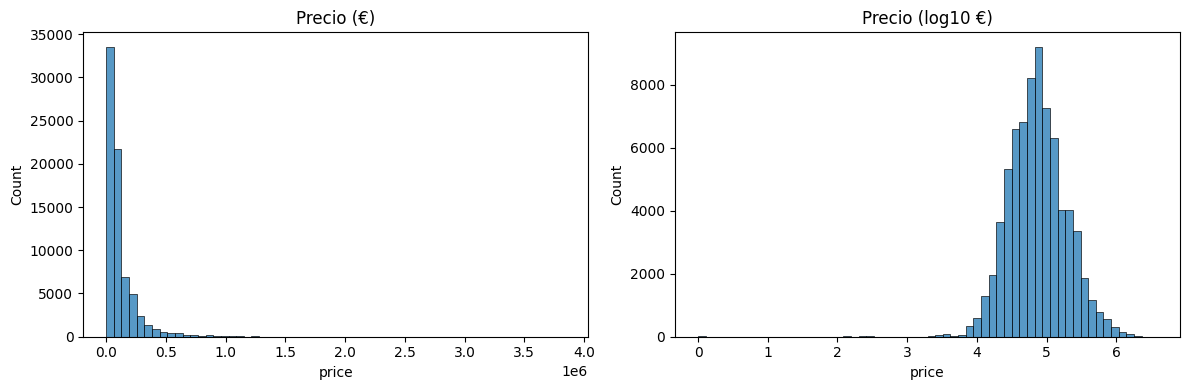

Precios por debajo de 1.000 €: 68


property_type
Farm House        1
Flat              7
House            33
Lower Portion    12
Room              2
Upper Portion    13
dtype: int64

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], bins=60, ax=axes[0])
axes[0].set_title("Precio (€)")
sns.histplot(np.log10(df["price"].clip(lower=1)), bins=60, ax=axes[1])
axes[1].set_title("Precio (log10 €)")
plt.tight_layout()
plt.show()

print("Precios por debajo de 1.000 €:", (df["price"] < 1000).sum())
df[df["price"] < 1000].groupby("property_type").size()

**Decisión 3: precio mínimo.** Por debajo de 1.000 € (unas 180.000 rupias) no hay ninguna casa, piso ni piso parcial a la venta con sentido. Son pocos anuncios (0,1 %) y no se pueden corregir, así que **se eliminan**.

In [53]:
n_antes = len(df)
df = df[df["price"] >= 1000].reset_index(drop=True)
print(f"Filas eliminadas por precio < 1.000 €: {n_antes - len(df)}")

Filas eliminadas por precio < 1.000 €: 68


**Decisión 4: precios altos, se conservan.** Calculamos cuántos anuncios quedan fuera del criterio IQR y qué efecto tiene un logaritmo.

In [54]:
q1, q3 = df["price"].quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
n_altos = (df["price"] > limite).sum()
print(f"Límite superior IQR: {limite:,.0f} € -> {n_altos} anuncios ({n_altos / len(df):.1%})")
print(f"Asimetría de price:      {df['price'].skew():.2f}")
print(f"Asimetría de log(price): {np.log(df['price']).skew():.2f}")

Límite superior IQR: 268,638 € -> 6544 anuncios (8.8%)
Asimetría de price:      4.98
Asimetría de log(price): 0.20


Hay un grupo grande de anuncios por encima del límite IQR, pero **no se eliminan**: son propiedades caras de verdad (casas grandes en zonas como DHA o Bani Gala), no errores. Quitarlos haría que el modelo no supiera estimar el segmento alto.

**Acción:** mantenerlos y tratar la asimetría con `log(price)` como variable objetivo (se decide en el EDA y en la fase de modelado).

In [55]:
print(f"Filas de partida de esta vuelta: {n_inicial_3v}")
print(f"Filas finales:                     {len(df)}")
print(f"Filas eliminadas en total:         {n_inicial_3v - len(df)}")
df.shape

Filas de partida de esta vuelta: 74234
Filas finales:                     74150
Filas eliminadas en total:         84


(74150, 11)

### Resumen de la tercera vuelta

| Hallazgo | Acción | Justificación | Filas eliminadas |
|---|---|---|---|
| `Total_Area` < 10 m² (en realidad 0 m²) | Eliminar | El cero es un dato ausente, no recuperable | 7 |
| `Upper Portion`, `Lower Portion`, `Penthouse` y `Room` con más de 2.500 m² | Eliminar | Una parte de una casa no puede superar a una casa entera (mismo límite que `House`) | 157 |
| `Farm House` con superficies muy grandes | Conservar | Son valores atípicos reales | 0 |
| `price` < 1.000 € | Eliminar | No corresponde a una venta real y no se puede corregir | 57 |
| `price` por encima del límite IQR | Conservar | Propiedades caras reales; se trata con `log(price)` | 0 |
